## 1. Install dependencies

In [1]:
import sys, subprocess, importlib.util

need = {"transformers": "transformers", "torch": "torch", "sklearn": "scikit-learn", "pandas": "pandas",
        "numpy": "numpy", "matplotlib": "matplotlib", "tqdm": "tqdm"}
missing = [pkg for mod, pkg in need.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All requirements already installed.")

All requirements already installed.


## 2. Configuration

In [2]:
import os, random, urllib.request
import numpy as np, pandas as pd

SEED       = 42
N_SAMPLES  = 50000          # samples per task (balanced over classes)
TEST_SIZE  = 0.10           # 90:10 split
MODEL_NAME = "bert-base-uncased"   # 12 encoder layers -> 12 models per task. (Lightweight alternative: "distilbert-base-uncased", 6 layers)
POOLING    = "mean"         # "mean" = average of token vectors (padding ignored), "cls" = [CLS] vector
MAX_LEN    = 128            # tokens (all SentEval sentences fit)
BATCH_SIZE = 128
INCLUDE_EMBEDDING_LAYER = False   # True adds layer 0 (input embeddings) as an extra baseline
LR_C       = 1.0            # inverse L2 regularisation strength of the logistic regression
LR_MAX_ITER = 500

random.seed(SEED); np.random.seed(SEED)

BASE_URL = "https://raw.githubusercontent.com/facebookresearch/SentEval/main/data/probing/"
TASKS = {"SentLen": "sentence_length.txt", "BShift": "bigram_shift.txt", "SubjNum": "subj_number.txt"}

DATA_DIR, FEAT_DIR, OUT_DIR = "probing_work/data", "probing_work/features", "probing_work/results"
for d in (DATA_DIR, FEAT_DIR, OUT_DIR): os.makedirs(d, exist_ok=True)

## 3. Download the data

In [3]:
for task, fname in TASKS.items():
    path = f"{DATA_DIR}/{fname}"
    if not os.path.exists(path):
        urllib.request.urlretrieve(BASE_URL + fname, path)
    n = sum(1 for _ in open(path, encoding="utf-8"))
    print(f"{fname}: {n} lines")
print(open(f"{DATA_DIR}/bigram_shift.txt", encoding="utf-8").readline())   # format: split <TAB> label <TAB> sentence

sentence_length.txt: 119988 lines
bigram_shift.txt: 120000 lines
subj_number.txt: 120000 lines
tr	I	A week she 'd been with the man , just a week , and she had survived barely the ups and downs .



## 4. Balanced sampling and stratified 90:10 split
SentEval's own train/val/test partition is ignored: all lines are pooled, exact duplicate sentences are removed, then **50,000 sentences are drawn with the same number per class** (SentLen: 8,334 or 8,333 per class over 6 classes; BShift and SubjNum: 25,000 per class). The sample is then split 90:10 with **stratification**, so the class balance is kept in both train and test.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

def load_task(fname):
    rows = []
    with open(f"{DATA_DIR}/{fname}", encoding="utf-8") as f:
        for line in f:
            parts = line.rstrip("\n").split("\t", 2)        # split, label, sentence
            if len(parts) == 3:
                rows.append((parts[1], parts[2]))
    df = pd.DataFrame(rows, columns=["label", "text"])
    return df.drop_duplicates(subset=["text"]).reset_index(drop=True)

def balanced_sample(df, n_total, seed):
    classes = sorted(df["label"].unique()); k = len(classes)
    base, extra = divmod(n_total, k)
    parts = []
    for i, c in enumerate(classes):
        n_c = base + (1 if i < extra else 0)
        g = df[df["label"] == c]
        assert len(g) >= n_c, f"class {c}: only {len(g)} sentences available, need {n_c}"
        parts.append(g.sample(n=n_c, random_state=seed))
    return pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True)

data = {}
for task, fname in TASKS.items():
    df = balanced_sample(load_task(fname), N_SAMPLES, SEED)
    le = LabelEncoder().fit(df["label"]); df["y"] = le.transform(df["label"])
    tr, te = train_test_split(df, test_size=TEST_SIZE, stratify=df["y"], random_state=SEED)
    data[task] = {"train": tr.reset_index(drop=True), "test": te.reset_index(drop=True), "classes": list(le.classes_)}

    print(f"\n=== {task}: {len(df)} samples, {len(le.classes_)} classes {list(le.classes_)} ===")
    print(pd.DataFrame({"train": tr["label"].value_counts().sort_index(), "test": te["label"].value_counts().sort_index()}))
    print("train/test sizes:", len(tr), len(te))
    print("example:", tr.iloc[0]["label"], "|", tr.iloc[0]["text"])


=== SentLen: 50000 samples, 6 classes ['0', '1', '2', '3', '4', '5'] ===
       train  test
label             
0       7500   834
1       7500   834
2       7500   833
3       7500   833
4       7500   833
5       7500   833
train/test sizes: 45000 5000
example: 4 | No matter how much using violence seemed to be justified , the results could never be worth it , could they ?

=== BShift: 50000 samples, 2 classes ['I', 'O'] ===
       train  test
label             
I      22500  2500
O      22500  2500
train/test sizes: 45000 5000
example: I | I know as hold I Rachel in my arms that I , too , had no choice in falling in love .

=== SubjNum: 50000 samples, 2 classes ['NN', 'NNS'] ===
       train  test
label             
NN     22500  2500
NNS    22500  2500
train/test sizes: 45000 5000
example: NN | A fire dragon , wherever it was , was hitting this man 's mind with the power of a speeding truck .


## 5. BERT sentence representations from every encoder layer
For each sentence the hidden states of all encoder layers are mean-pooled over the real tokens (padding ignored), giving one 768-d vector per layer. Features are cached on disk, so re-running this cell is fast.

In [5]:
import torch
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME, output_hidden_states=True).to(device).eval()
N_LAYERS = model.config.num_hidden_layers
LAYERS = list(range(0 if INCLUDE_EMBEDDING_LAYER else 1, N_LAYERS + 1))     # hidden_states[0] = embeddings, [1..N] = encoder layers
print(f"{MODEL_NAME}: {N_LAYERS} encoder layers -> {len(LAYERS)} probing models per task")

@torch.no_grad()
def extract(texts, batch_size=BATCH_SIZE):
    order = np.argsort([len(t) for t in texts])             # similar lengths together -> little padding
    out = np.zeros((len(texts), len(LAYERS), model.config.hidden_size), dtype=np.float16)
    for s in tqdm(range(0, len(texts), batch_size), leave=False):
        idx = order[s:s + batch_size]
        enc = tokenizer([texts[i] for i in idx], padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt").to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
            hs = model(**enc).hidden_states
        mask = enc["attention_mask"].unsqueeze(-1).float()
        feats = []
        for l in LAYERS:
            h = hs[l].float()
            feats.append(h[:, 0] if POOLING == "cls" else (h * mask).sum(1) / mask.sum(1))
        out[idx] = torch.stack(feats, 1).cpu().numpy().astype(np.float16)
    return out

feats = {}
tag = f"{MODEL_NAME.replace('/', '_')}_{POOLING}_{int(INCLUDE_EMBEDDING_LAYER)}"
for task in TASKS:
    feats[task] = {}
    for split in ("train", "test"):
        p = f"{FEAT_DIR}/{task}_{split}_{tag}.npy"
        if os.path.exists(p):
            feats[task][split] = np.load(p)
        else:
            feats[task][split] = extract(data[task][split]["text"].tolist())
            np.save(p, feats[task][split])
        print(task, split, feats[task][split].shape)

device: cuda


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

... (12 outputs left out)

  0%|          | 0/352 [00:00<?, ?it/s]

SubjNum train (45000, 12, 768)


  0%|          | 0/40 [00:00<?, ?it/s]

SubjNum test (5000, 12, 768)


## 6. Train one logistic regression per layer
For each task and each layer a separate multinomial **logistic regression** (L2-regularised, features standardised with statistics from the training set only) is trained on the training representations and evaluated on the held-out test set. That gives 12 models per task for BERT-base.

In [6]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

records = []
for task in TASKS:
    ytr, yte = data[task]["train"]["y"].values, data[task]["test"]["y"].values
    for j, layer in enumerate(LAYERS):
        t0 = time.time()
        Xtr = feats[task]["train"][:, j, :].astype(np.float32)
        Xte = feats[task]["test"][:, j, :].astype(np.float32)
        sc = StandardScaler().fit(Xtr)
        clf = LogisticRegression(C=LR_C, max_iter=LR_MAX_ITER).fit(sc.transform(Xtr), ytr)
        pred = clf.predict(sc.transform(Xte))
        rec = {"task": task, "layer": layer,
               "train_acc": accuracy_score(ytr, clf.predict(sc.transform(Xtr))) * 100,
               "test_acc": accuracy_score(yte, pred) * 100,
               "test_macro_f1": f1_score(yte, pred, average="macro") * 100}
        records.append(rec)
        print(f"{task:8s} layer {layer:2d}  train {rec['train_acc']:.2f}  test {rec['test_acc']:.2f}  ({time.time() - t0:.0f}s)")

results = pd.DataFrame(records)
results.to_csv(f"{OUT_DIR}/probing_results.csv", index=False)

SentLen  layer  1  train 99.38  test 95.42  (34s)
SentLen  layer  2  train 99.03  test 95.18  (36s)
SentLen  layer  3  train 99.06  test 95.66  (35s)
SentLen  layer  4  train 98.40  test 95.02  (50s)
SentLen  layer  5  train 97.81  test 94.20  (48s)
SentLen  layer  6  train 96.97  test 92.88  (52s)
SentLen  layer  7  train 95.88  test 91.54  (50s)
SentLen  layer  8  train 95.10  test 91.28  (46s)
SentLen  layer  9  train 93.11  test 89.06  (46s)
SentLen  layer 10  train 90.56  test 86.32  (51s)
SentLen  layer 11  train 88.44  test 84.44  (49s)
SentLen  layer 12  train 87.16  test 83.20  (48s)
BShift   layer  1  train 59.64  test 56.68  (8s)
BShift   layer  2  train 72.52  test 70.90  (6s)
BShift   layer  3  train 83.63  test 83.06  (7s)
BShift   layer  4  train 87.28  test 86.48  (5s)
BShift   layer  5  train 88.61  test 88.16  (4s)
BShift   layer  6  train 89.93  test 89.40  (4s)
BShift   layer  7  train 90.84  test 90.64  (5s)
BShift   layer  8  train 91.79  test 91.62  (5s)
BShift  

## 7. Results: layer-wise comparison on the test sets

Test accuracy (%) per layer


task,SentLen,BShift,SubjNum
layer,,,
1,95.42,56.68,84.32
2,95.18,70.90,83.72
3,95.66,83.06,85.62
4,95.02,86.48,86.44
5,94.20,88.16,88.58
6,92.88,89.40,88.34
7,91.54,90.64,88.52
8,91.28,91.62,88.92
9,89.06,91.26,89.28


Best layer per task:


,best_layer,best_test_acc,chance
SentLen,3,95.66,16.7
BShift,8,91.62,50.0
SubjNum,9,89.28,50.0


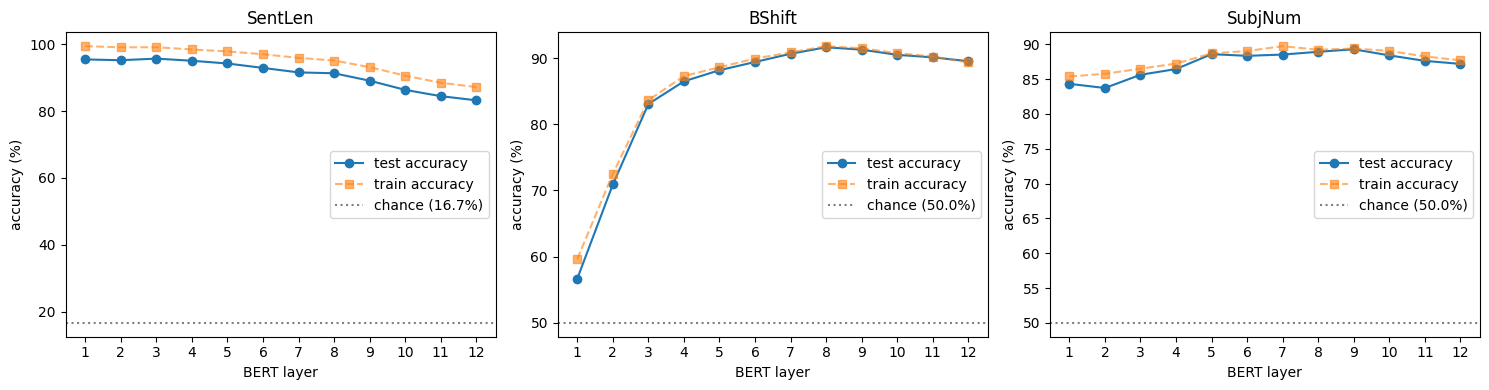

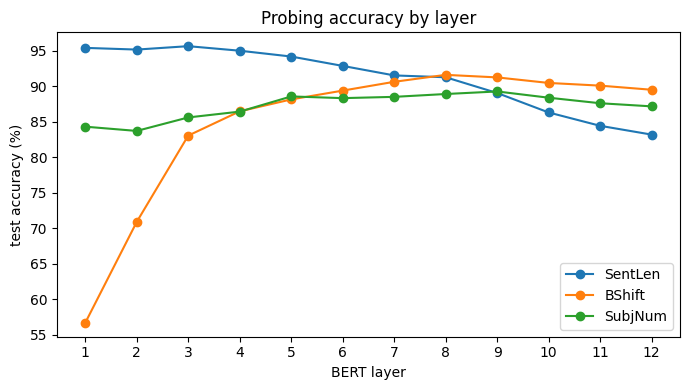

In [7]:
import matplotlib.pyplot as plt

acc = results.pivot(index="layer", columns="task", values="test_acc").round(2)[list(TASKS)]
f1  = results.pivot(index="layer", columns="task", values="test_macro_f1").round(2)[list(TASKS)]
chance = {t: 100 / len(data[t]["classes"]) for t in TASKS}

print("Test accuracy (%) per layer"); display(acc)
print("Best layer per task:"); display(pd.DataFrame({"best_layer": acc.idxmax(), "best_test_acc": acc.max(), "chance": pd.Series(chance).round(1)}))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, t in zip(axes, TASKS):
    ax.plot(acc.index, acc[t], marker="o", label="test accuracy")
    tr = results[results.task == t].set_index("layer")["train_acc"]
    ax.plot(tr.index, tr.values, marker="s", ls="--", alpha=0.6, label="train accuracy")
    ax.axhline(chance[t], color="gray", ls=":", label=f"chance ({chance[t]:.1f}%)")
    ax.set_title(t); ax.set_xlabel("BERT layer"); ax.set_ylabel("accuracy (%)"); ax.set_xticks(list(acc.index)); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/layerwise_accuracy.png", dpi=150); plt.show()

plt.figure(figsize=(7, 4))
for t in TASKS: plt.plot(acc.index, acc[t], marker="o", label=t)
plt.xlabel("BERT layer"); plt.ylabel("test accuracy (%)"); plt.xticks(list(acc.index)); plt.legend(); plt.title("Probing accuracy by layer")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/all_tasks.png", dpi=150); plt.show()

### Result analysis (complete after your run)

Discuss the table and plots above, for example:

1. **Where is each property best encoded?** Report the best layer for SentLen, BShift and SubjNum. Studies of BERT's layers (e.g. Jawahar et al., 2019, *What does BERT learn about the structure of language?*) report that **surface** information such as sentence length is strongest in the lower layers and fades with depth, **syntactic** information such as bigram shift peaks in the middle layers, and **semantic** information such as subject number is strongest in the middle-to-upper layers. Check whether your curves follow this pattern, and say where they differ.
2. **Difficulty of the tasks:** compare absolute accuracies to chance (1/6 for SentLen, 1/2 for BShift and SubjNum) and across tasks. Which task is easiest for a linear probe?
3. **Compare with the papers:** Conneau et al. (arXiv 1805.01070) probe sentence encoders (BiLSTM variants, Gated ConvNet and a CBOW baseline) on the same three tasks. Take the accuracies from the results tables of the papers and discuss whether BERT's best layer is above, similar to or below them, and how the length / syntax / semantics split from the paper shows up in BERT's layers.
4. **Train vs test accuracy:** a large gap means the 768-d probe overfits (compare the dashed and solid lines); with 45,000 training samples this should be small.
5. **Pooling and probe choice:** mean pooling was used. Mention that a different pooling (`POOLING = "cls"`) or a non-linear probe could change the numbers, and that a linear probe measures what is *linearly decodable* from each layer, not what the model uses.
6. **Limitations:** one run per setting (no seeds / confidence intervals), a single balanced sample of 50,000 sentences, and standardised features with L2-regularised logistic regression.